# Classification Track (Part A) — Verdict Outcome Tendency Prediction
Loads preprocessed data from `preprocessing.ipynb` and runs the 5 Part-A classification algorithms and their evaluation.

**Requires `preprocessing.ipynb` to have been run first** (produces `data/processed/model_ready_data.pkl`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier,
                               AdaBoostClassifier, GradientBoostingClassifier, BaggingClassifier)
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVR, SVC
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error, accuracy_score, precision_score,
                              recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
                              classification_report)
import time
import warnings
warnings.filterwarnings("ignore", category=UserWarning)  # harmless DataFrame/array feature-name mismatch

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid", palette="colorblind")
RANDOM_STATE = 42

### Load preprocessed train/test data

In [2]:
import joblib

artifacts = joblib.load("../data/processed/model_ready_data.pkl")
X_train_final = artifacts["X_train_final"]
X_test_final = artifacts["X_test_final"]
y_clf_train = artifacts["y_clf_train"]
y_clf_test = artifacts["y_clf_test"]
RANDOM_STATE = artifacts["RANDOM_STATE"]

print("Loaded preprocessed data. X_train_final shape:", X_train_final.shape)

Loaded preprocessed data. X_train_final shape: (194879, 37)


---
### Shared setup — class order, result trackers, evaluation function

In [3]:
CLASS_LABELS = sorted(y_clf_train.unique().tolist())
print("Class order:", CLASS_LABELS)

results_clf = []
fitted_models_clf = {}
test_preds_clf = {}
test_probas_clf = {}

def evaluate_classifier(name, y_true, y_pred, y_proba, fit_seconds, classes):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    roc_auc = roc_auc_score(y_true, y_proba, multi_class="ovr", average="weighted", labels=classes)

    print(f"\n===== {name} =====")
    print(f"Accuracy={acc:.4f}  Precision(weighted)={prec:.4f}  Recall(weighted)={rec:.4f}  "
          f"F1(weighted)={f1:.4f}  ROC-AUC(OvR, weighted)={roc_auc:.4f}  (fit time {fit_seconds:.1f}s)")
    print(classification_report(y_true, y_pred, labels=classes, zero_division=0))

    cm = confusion_matrix(y_true, y_pred, labels=classes)
    fig, ax = plt.subplots(figsize=(6, 5))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
    disp.plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
    ax.set_title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

    results_clf.append({"Model": name, "Accuracy": acc, "Precision": prec, "Recall": rec,
                         "F1": f1, "ROC_AUC_OvR": roc_auc, "Fit_Seconds": fit_seconds})
    return acc, prec, rec, f1, roc_auc

Class order: ['Dismissed', 'Judgment', 'Settled', 'Statistical', 'Transferred']


#### 1. Logistic Regression

c:\Users\krith\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)



===== Logistic Regression =====
Accuracy=0.4425  Precision(weighted)=0.5654  Recall(weighted)=0.4425  F1(weighted)=0.4637  ROC-AUC(OvR, weighted)=0.7576  (fit time 11.3s)
              precision    recall  f1-score   support

   Dismissed       0.75      0.36      0.49     22863
    Judgment       0.42      0.41      0.41      9620
     Settled       0.47      0.63      0.54     10772
 Statistical       0.10      0.47      0.16      1485
 Transferred       0.28      0.46      0.34      3980

    accuracy                           0.44     48720
   macro avg       0.40      0.47      0.39     48720
weighted avg       0.57      0.44      0.46     48720



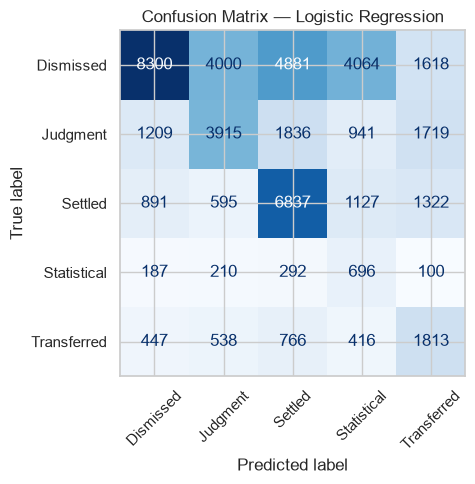

(0.4425492610837438,
 0.5654141831270527,
 0.4425492610837438,
 0.4637459505516463,
 0.7575999174681162)

In [4]:
t0 = time.time()
log_reg = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
log_reg.fit(X_train_final, y_clf_train)
fit_seconds = time.time() - t0

pred_log = log_reg.predict(X_test_final)
proba_log = log_reg.predict_proba(X_test_final)

fitted_models_clf["Logistic Regression"] = log_reg
test_preds_clf["Logistic Regression"] = pred_log
test_probas_clf["Logistic Regression"] = proba_log

evaluate_classifier("Logistic Regression", y_clf_test, pred_log, proba_log, fit_seconds,
                     classes=log_reg.classes_.tolist())

Coefficient / odds interpretation — Logistic Regression

In [5]:
coef_df = pd.DataFrame(log_reg.coef_, index=log_reg.classes_, columns=X_train_final.columns)
odds_ratios = np.exp(coef_df)

print("Top 5 features (by |coefficient|) driving each class, with their odds ratio:")
for cls in log_reg.classes_:
    top_feats = coef_df.loc[cls].sort_values(key=abs, ascending=False).head(5)
    print(f"\n{cls}:")
    for feat, coef_val in top_feats.items():
        print(f"    {feat:30s}  coef={coef_val:+.3f}   odds_ratio={odds_ratios.loc[cls, feat]:.3f}")

Top 5 features (by |coefficient|) driving each class, with their odds ratio:

Dismissed:
    PC30                            coef=+1.100   odds_ratio=3.003
    PC34                            coef=-0.907   odds_ratio=0.404
    PC33                            coef=-0.840   odds_ratio=0.432
    PC35                            coef=-0.776   odds_ratio=0.460
    PC29                            coef=-0.659   odds_ratio=0.518

Judgment:
    PC36                            coef=+1.149   odds_ratio=3.154
    PC30                            coef=-0.908   odds_ratio=0.403
    PC27                            coef=-0.807   odds_ratio=0.446
    PC37                            coef=+0.797   odds_ratio=2.219
    PC33                            coef=-0.747   odds_ratio=0.474

Settled:
    PC28                            coef=+0.952   odds_ratio=2.592
    PC11                            coef=-0.687   odds_ratio=0.503
    PC8                             coef=-0.674   odds_ratio=0.509
    PC4            

#### 2. KNN Classifier

Stratified subsample class balance:
CASE_OUTCOME
Dismissed      0.469
Settled        0.221
Judgment       0.197
Transferred    0.082
Statistical    0.030
Name: proportion, dtype: float64

===== KNN Classifier =====
Accuracy=0.5711  Precision(weighted)=0.5599  Recall(weighted)=0.5711  F1(weighted)=0.5580  ROC-AUC(OvR, weighted)=0.7630  (fit time 0.3s)
              precision    recall  f1-score   support

   Dismissed       0.63      0.73      0.68     22863
    Judgment       0.52      0.41      0.46      9620
     Settled       0.50      0.55      0.53     10772
 Statistical       0.50      0.18      0.27      1485
 Transferred       0.43      0.24      0.31      3980

    accuracy                           0.57     48720
   macro avg       0.52      0.42      0.45     48720
weighted avg       0.56      0.57      0.56     48720



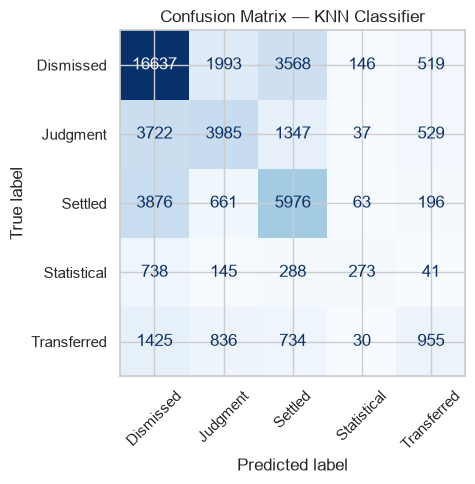

(0.5711412151067323,
 0.5599127419141421,
 0.5711412151067323,
 0.5580176517993961,
 0.7630420076127565)

In [6]:
KNN_SVC_SAMPLE_SIZE = 15000
X_train_small, _, y_clf_train_small, _ = train_test_split(
    X_train_final, y_clf_train,
    train_size=KNN_SVC_SAMPLE_SIZE, stratify=y_clf_train, random_state=RANDOM_STATE
)
print("Stratified subsample class balance:")
print(y_clf_train_small.value_counts(normalize=True).round(3))

t0 = time.time()
knn_clf = KNeighborsClassifier(n_neighbors=10, weights="distance", n_jobs=-1)
knn_clf.fit(X_train_small, y_clf_train_small)
fit_seconds = time.time() - t0

pred_knn_clf = knn_clf.predict(X_test_final)
proba_knn_clf = knn_clf.predict_proba(X_test_final)

fitted_models_clf["KNN Classifier"] = knn_clf
test_preds_clf["KNN Classifier"] = pred_knn_clf
test_probas_clf["KNN Classifier"] = proba_knn_clf

evaluate_classifier("KNN Classifier", y_clf_test, pred_knn_clf, proba_knn_clf, fit_seconds,
                     classes=knn_clf.classes_.tolist())

#### 3. Naive Bayes (Gaussian)


===== Naive Bayes (Gaussian) =====
Accuracy=0.5017  Precision(weighted)=0.5067  Recall(weighted)=0.5017  F1(weighted)=0.4997  ROC-AUC(OvR, weighted)=0.7189  (fit time 2.6s)
              precision    recall  f1-score   support

   Dismissed       0.62      0.60      0.61     22863
    Judgment       0.41      0.39      0.40      9620
     Settled       0.46      0.55      0.50     10772
 Statistical       0.14      0.26      0.18      1485
 Transferred       0.34      0.15      0.21      3980

    accuracy                           0.50     48720
   macro avg       0.39      0.39      0.38     48720
weighted avg       0.51      0.50      0.50     48720



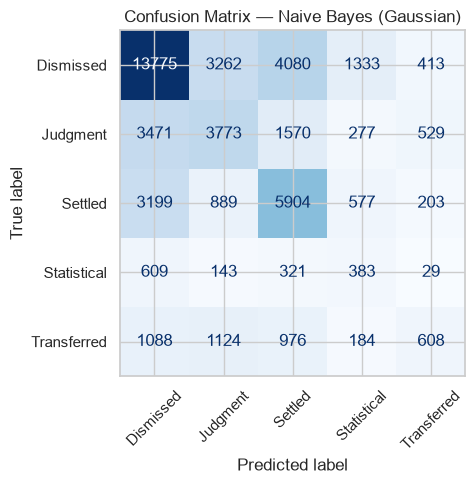

(0.5017036124794746,
 0.5066908747810341,
 0.5017036124794746,
 0.499741511399264,
 0.7189336854132348)

In [7]:
t0 = time.time()
nb_clf = GaussianNB()
nb_clf.fit(X_train_final, y_clf_train)
fit_seconds = time.time() - t0

pred_nb = nb_clf.predict(X_test_final)
proba_nb = nb_clf.predict_proba(X_test_final)

fitted_models_clf["Naive Bayes (Gaussian)"] = nb_clf
test_preds_clf["Naive Bayes (Gaussian)"] = pred_nb
test_probas_clf["Naive Bayes (Gaussian)"] = proba_nb

evaluate_classifier("Naive Bayes (Gaussian)", y_clf_test, pred_nb, proba_nb, fit_seconds,
                     classes=nb_clf.classes_.tolist())

#### 4. Decision Tree Classifier


===== Decision Tree Classifier =====
Accuracy=0.5445  Precision(weighted)=0.6202  Recall(weighted)=0.5445  F1(weighted)=0.5624  ROC-AUC(OvR, weighted)=0.8021  (fit time 68.7s)
              precision    recall  f1-score   support

   Dismissed       0.76      0.51      0.61     22863
    Judgment       0.62      0.53      0.57      9620
     Settled       0.50      0.67      0.57     10772
 Statistical       0.16      0.47      0.24      1485
 Transferred       0.30      0.50      0.37      3980

    accuracy                           0.54     48720
   macro avg       0.47      0.53      0.47     48720
weighted avg       0.62      0.54      0.56     48720



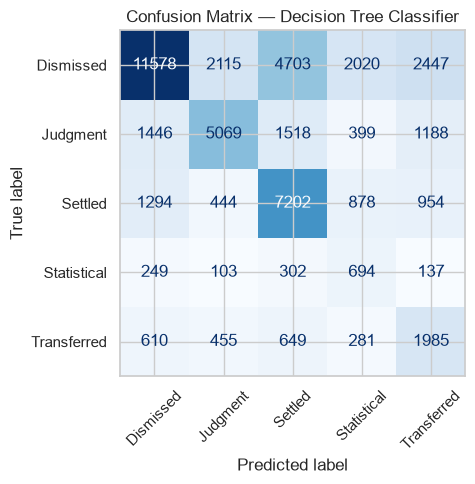

(0.5444991789819376,
 0.620157077628443,
 0.5444991789819376,
 0.5624157650907027,
 0.8021101993315762)

In [8]:
t0 = time.time()
dt_clf = DecisionTreeClassifier(max_depth=10, class_weight="balanced", random_state=RANDOM_STATE)
dt_clf.fit(X_train_final, y_clf_train)
fit_seconds = time.time() - t0

pred_dt_clf = dt_clf.predict(X_test_final)
proba_dt_clf = dt_clf.predict_proba(X_test_final)

fitted_models_clf["Decision Tree Classifier"] = dt_clf
test_preds_clf["Decision Tree Classifier"] = pred_dt_clf
test_probas_clf["Decision Tree Classifier"] = proba_dt_clf

evaluate_classifier("Decision Tree Classifier", y_clf_test, pred_dt_clf, proba_dt_clf, fit_seconds,
                     classes=dt_clf.classes_.tolist())

Tree visualisation (top 3 levels) — Decision Tree Classifier

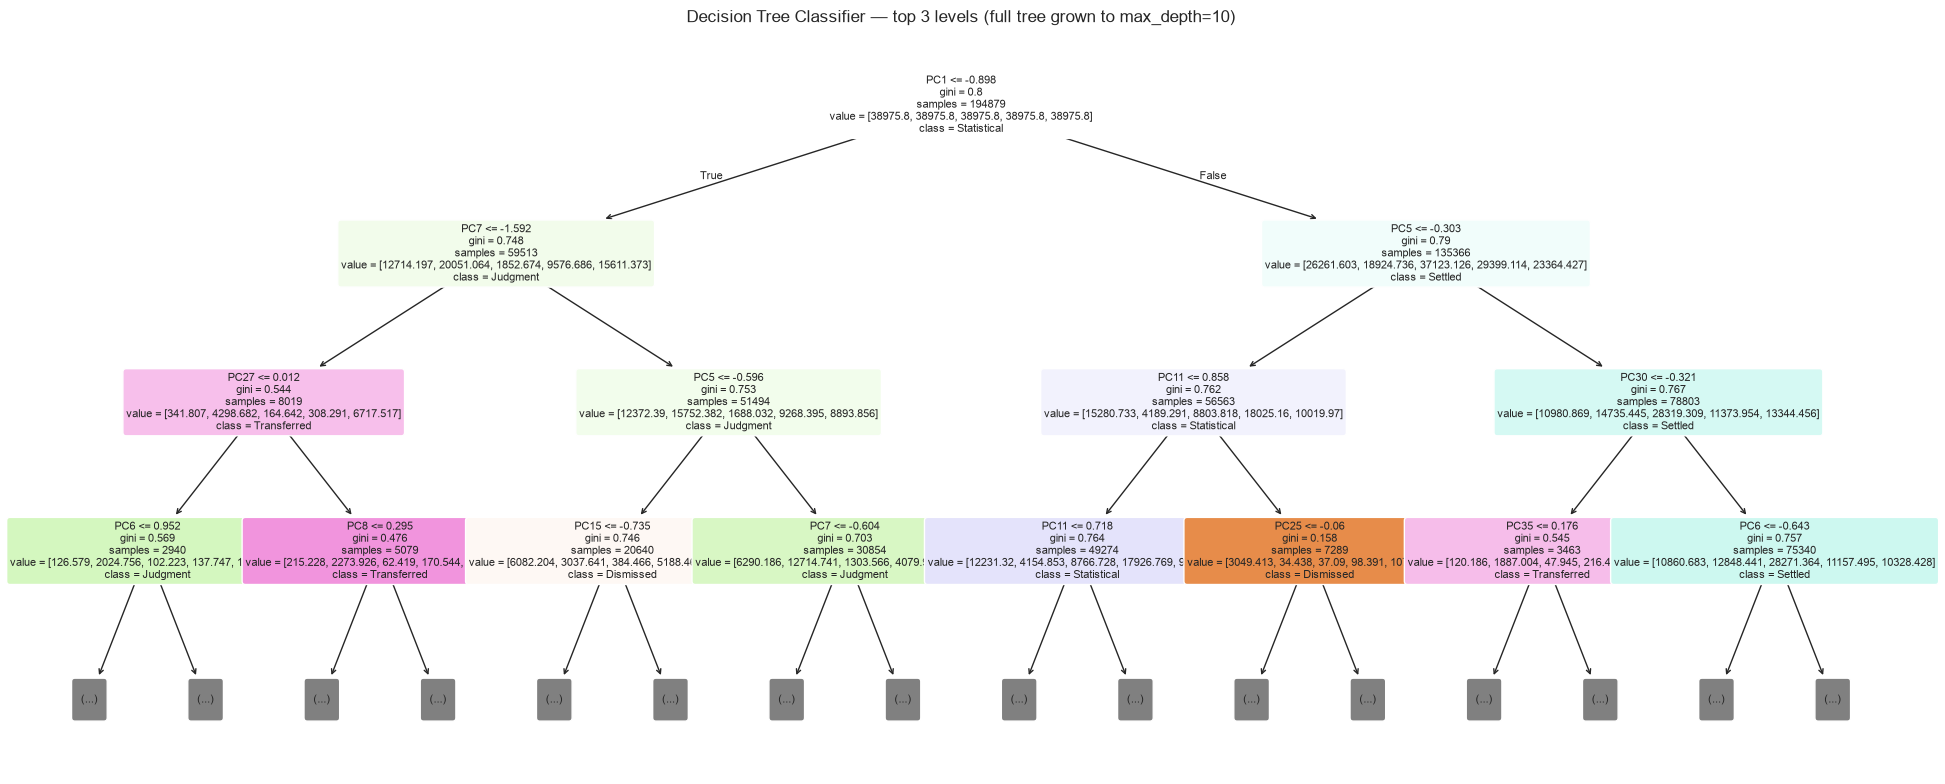

In [9]:
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(dt_clf, max_depth=3, feature_names=X_train_final.columns, class_names=dt_clf.classes_,
          filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title("Decision Tree Classifier — top 3 levels (full tree grown to max_depth=10)")
plt.tight_layout()
plt.show()

#### 5. SVC (Support Vector Classifier)

c:\Users\krith\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



===== SVC =====
Accuracy=0.5240  Precision(weighted)=0.6067  Recall(weighted)=0.5240  F1(weighted)=0.5370  ROC-AUC(OvR, weighted)=0.7995  (fit time 194.8s)
              precision    recall  f1-score   support

   Dismissed       0.78      0.46      0.58     22863
    Judgment       0.51      0.47      0.49      9620
     Settled       0.48      0.74      0.58     10772
 Statistical       0.14      0.39      0.20      1485
 Transferred       0.34      0.46      0.39      3980

    accuracy                           0.52     48720
   macro avg       0.45      0.51      0.45     48720
weighted avg       0.61      0.52      0.54     48720



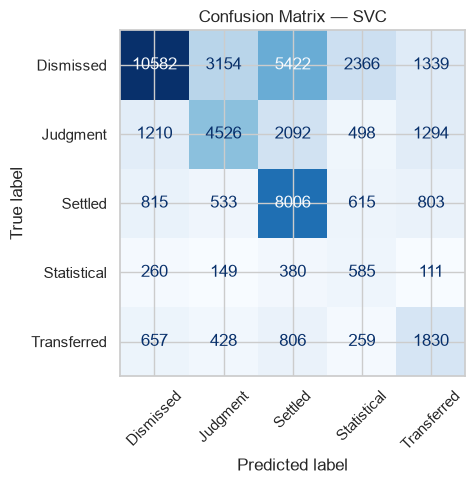

(0.5239942528735633,
 0.6067431771078464,
 0.5239942528735633,
 0.53696629968073,
 0.7994675424738181)

In [10]:
t0 = time.time()
svc_clf = SVC(kernel="rbf", C=1.0, probability=True, class_weight="balanced", random_state=RANDOM_STATE)
svc_clf.fit(X_train_small, y_clf_train_small)
fit_seconds = time.time() - t0

pred_svc = svc_clf.predict(X_test_final)
proba_svc = svc_clf.predict_proba(X_test_final)

fitted_models_clf["SVC"] = svc_clf
test_preds_clf["SVC"] = pred_svc
test_probas_clf["SVC"] = proba_svc

evaluate_classifier("SVC", y_clf_test, pred_svc, proba_svc, fit_seconds, classes=svc_clf.classes_.tolist())

---
### Part A comparison table (5 algorithms)

In [11]:
comparison_clf_df = pd.DataFrame(results_clf).drop_duplicates(subset="Model", keep="last")
comparison_clf_df = comparison_clf_df.sort_values("F1", ascending=False).reset_index(drop=True)
comparison_clf_df.index = comparison_clf_df.index + 1
comparison_clf_df.insert(0, "Rank", comparison_clf_df.index)
comparison_clf_df[["Rank", "Model", "Accuracy", "Precision", "Recall", "F1", "ROC_AUC_OvR", "Fit_Seconds"]].round(4)

,Rank,Model,Accuracy,Precision,Recall,F1,ROC_AUC_OvR,Fit_Seconds
1,1,Decision Tree Classifier,0.5445,0.6202,0.5445,0.5624,0.8021,68.7201
2,2,KNN Classifier,0.5711,0.5599,0.5711,0.5580,0.7630,0.2839
3,3,SVC,0.5240,0.6067,0.5240,0.5370,0.7995,194.8054
4,4,Naive Bayes (Gaussian),0.5017,0.5067,0.5017,0.4997,0.7189,2.6170
5,5,Logistic Regression,0.4425,0.5654,0.4425,0.4637,0.7576,11.3237


---
## Classification Track — Part B (Algorithms 6–10)

#### 6. Random Forest Classifier


===== Random Forest Classifier =====
Accuracy=0.6164  Precision(weighted)=0.6735  Recall(weighted)=0.6164  F1(weighted)=0.6263  ROC-AUC(OvR, weighted)=0.8577  (fit time 23.7s)
              precision    recall  f1-score   support

   Dismissed       0.83      0.56      0.67     22863
    Judgment       0.64      0.63      0.63      9620
     Settled       0.54      0.76      0.63     10772
 Statistical       0.26      0.51      0.35      1485
 Transferred       0.39      0.54      0.46      3980

    accuracy                           0.62     48720
   macro avg       0.53      0.60      0.55     48720
weighted avg       0.67      0.62      0.63     48720



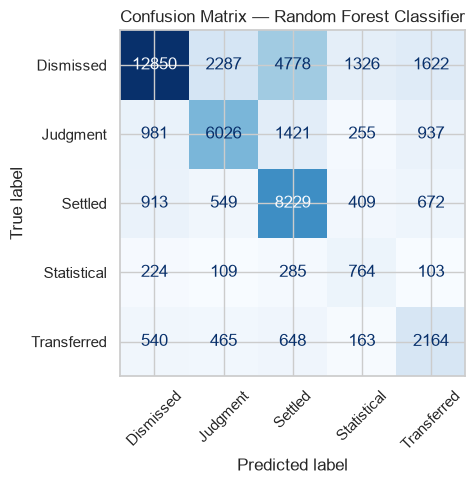

(0.6164408866995074,
 0.6735219841658026,
 0.6164408866995074,
 0.6263165276082587,
 0.8577105874908967)

In [12]:
t0 = time.time()
rf_clf = RandomForestClassifier(n_estimators=200, max_depth=15, class_weight="balanced",
                                 random_state=RANDOM_STATE, n_jobs=-1)
rf_clf.fit(X_train_final, y_clf_train)
fit_seconds = time.time() - t0

pred_rf_clf = rf_clf.predict(X_test_final)
proba_rf_clf = rf_clf.predict_proba(X_test_final)

fitted_models_clf["Random Forest Classifier"] = rf_clf
test_preds_clf["Random Forest Classifier"] = pred_rf_clf
test_probas_clf["Random Forest Classifier"] = proba_rf_clf

evaluate_classifier("Random Forest Classifier", y_clf_test, pred_rf_clf, proba_rf_clf, fit_seconds,
                     classes=rf_clf.classes_.tolist())

Feature importance — Random Forest Classifier

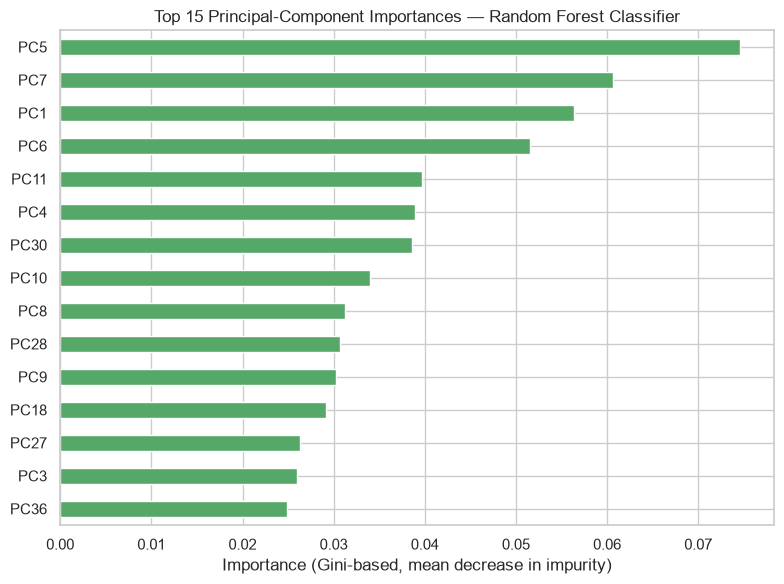

In [13]:
rf_importances = pd.Series(rf_clf.feature_importances_, index=X_train_final.columns)
top_rf = rf_importances.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 6))
top_rf.sort_values().plot(kind="barh", ax=ax, color="#55A868")
ax.set_title("Top 15 Principal-Component Importances — Random Forest Classifier")
ax.set_xlabel("Importance (Gini-based, mean decrease in impurity)")
plt.tight_layout()
plt.show()

#### 7. AdaBoost Classifier


===== AdaBoost Classifier =====
Accuracy=0.5449  Precision(weighted)=0.5113  Recall(weighted)=0.5449  F1(weighted)=0.4980  ROC-AUC(OvR, weighted)=0.7462  (fit time 167.9s)
              precision    recall  f1-score   support

   Dismissed       0.57      0.81      0.67     22863
    Judgment       0.51      0.31      0.38      9620
     Settled       0.50      0.45      0.47     10772
 Statistical       0.00      0.00      0.00      1485
 Transferred       0.43      0.03      0.05      3980

    accuracy                           0.54     48720
   macro avg       0.40      0.32      0.32     48720
weighted avg       0.51      0.54      0.50     48720



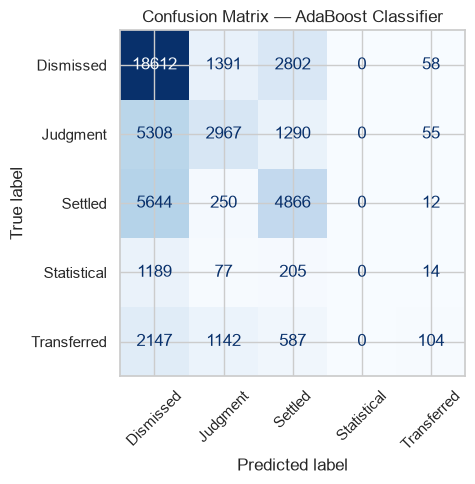

(0.5449302134646963,
 0.5113235191683168,
 0.5449302134646963,
 0.4979855777578692,
 0.7462022359833441)

In [14]:
t0 = time.time()
ada_clf = AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE)
ada_clf.fit(X_train_final, y_clf_train)
fit_seconds = time.time() - t0

pred_ada = ada_clf.predict(X_test_final)
proba_ada = ada_clf.predict_proba(X_test_final)

fitted_models_clf["AdaBoost Classifier"] = ada_clf
test_preds_clf["AdaBoost Classifier"] = pred_ada
test_probas_clf["AdaBoost Classifier"] = proba_ada

evaluate_classifier("AdaBoost Classifier", y_clf_test, pred_ada, proba_ada, fit_seconds,
                     classes=ada_clf.classes_.tolist())

Staged test accuracy and feature importance — AdaBoost Classifier

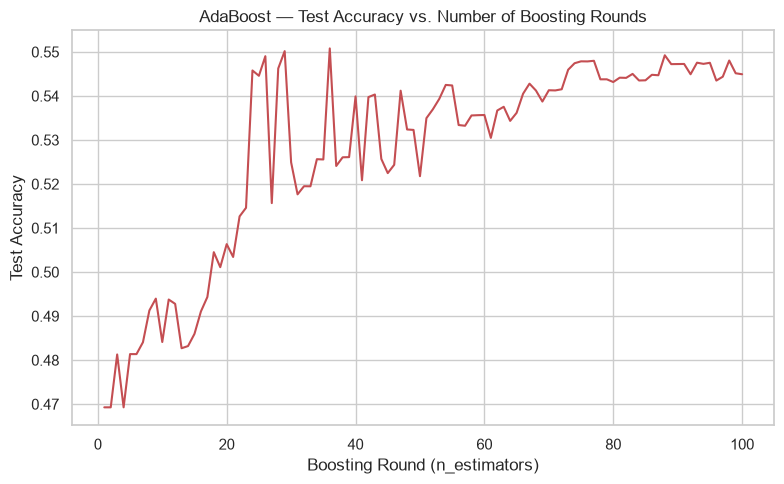

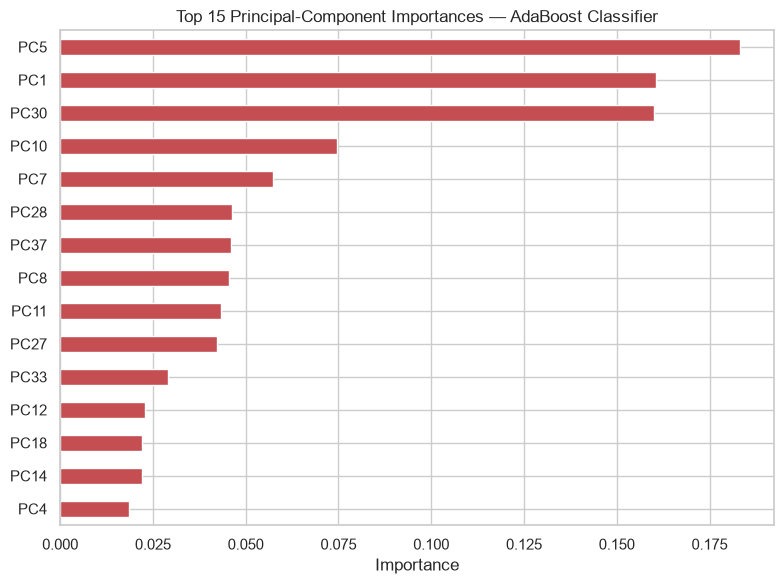

In [15]:
staged_acc = [accuracy_score(y_clf_test, pred) for pred in ada_clf.staged_predict(X_test_final)]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(1, len(staged_acc) + 1), staged_acc, color="#C44E52")
ax.set_title("AdaBoost — Test Accuracy vs. Number of Boosting Rounds")
ax.set_xlabel("Boosting Round (n_estimators)")
ax.set_ylabel("Test Accuracy")
plt.tight_layout()
plt.show()

ada_importances = pd.Series(ada_clf.feature_importances_, index=X_train_final.columns)
top_ada = ada_importances.sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(8, 6))
top_ada.sort_values().plot(kind="barh", ax=ax, color="#C44E52")
ax.set_title("Top 15 Principal-Component Importances — AdaBoost Classifier")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

#### 8. Gradient Boosting Classifier


===== Gradient Boosting Classifier =====
Accuracy=0.6255  Precision(weighted)=0.6365  Recall(weighted)=0.6255  F1(weighted)=0.6051  ROC-AUC(OvR, weighted)=0.8262  (fit time 1888.3s)
              precision    recall  f1-score   support

   Dismissed       0.65      0.80      0.72     22863
    Judgment       0.66      0.45      0.54      9620
     Settled       0.54      0.64      0.59     10772
 Statistical       0.87      0.15      0.25      1485
 Transferred       0.65      0.20      0.31      3980

    accuracy                           0.63     48720
   macro avg       0.68      0.45      0.48     48720
weighted avg       0.64      0.63      0.61     48720



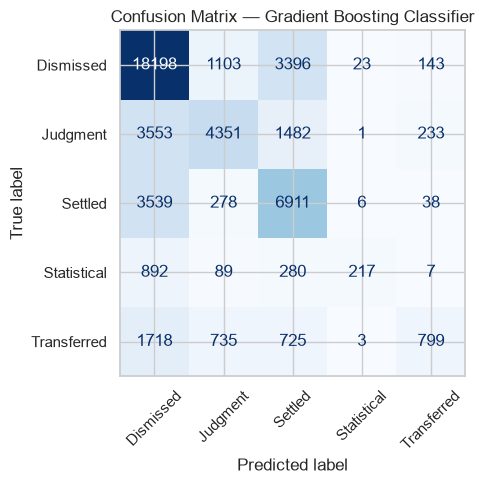

(0.6255336617405582,
 0.6365223968265589,
 0.6255336617405582,
 0.6050905861900253,
 0.82619812564472)

In [16]:
t0 = time.time()
gb_clf = GradientBoostingClassifier(n_estimators=60, max_depth=3, learning_rate=0.1, random_state=RANDOM_STATE)
gb_clf.fit(X_train_final, y_clf_train)
fit_seconds = time.time() - t0

pred_gb_clf = gb_clf.predict(X_test_final)
proba_gb_clf = gb_clf.predict_proba(X_test_final)

fitted_models_clf["Gradient Boosting Classifier"] = gb_clf
test_preds_clf["Gradient Boosting Classifier"] = pred_gb_clf
test_probas_clf["Gradient Boosting Classifier"] = proba_gb_clf

evaluate_classifier("Gradient Boosting Classifier", y_clf_test, pred_gb_clf, proba_gb_clf, fit_seconds,
                     classes=gb_clf.classes_.tolist())

Training deviance curve and feature importance — Gradient Boosting Classifier

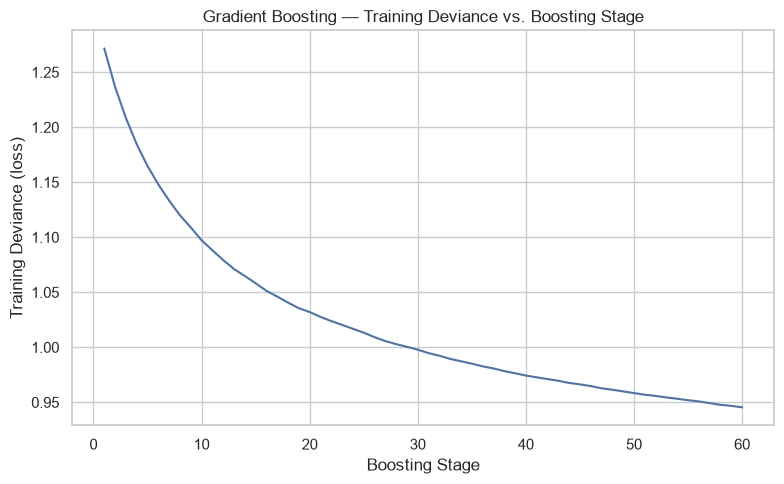

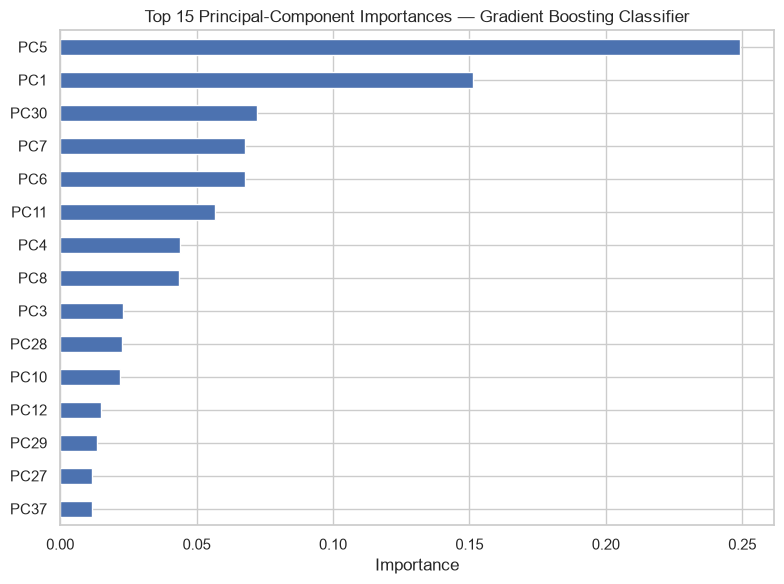

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(1, gb_clf.n_estimators_ + 1), gb_clf.train_score_, color="#4C72B0")
ax.set_title("Gradient Boosting — Training Deviance vs. Boosting Stage")
ax.set_xlabel("Boosting Stage")
ax.set_ylabel("Training Deviance (loss)")
plt.tight_layout()
plt.show()

gb_importances = pd.Series(gb_clf.feature_importances_, index=X_train_final.columns)
top_gb = gb_importances.sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(8, 6))
top_gb.sort_values().plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_title("Top 15 Principal-Component Importances — Gradient Boosting Classifier")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

#### 9. Bagging Classifier


===== Bagging Classifier =====
Accuracy=0.6329  Precision(weighted)=0.6721  Recall(weighted)=0.6329  F1(weighted)=0.6409  ROC-AUC(OvR, weighted)=0.8546  (fit time 168.8s)
              precision    recall  f1-score   support

   Dismissed       0.80      0.60      0.69     22863
    Judgment       0.67      0.64      0.66      9620
     Settled       0.55      0.76      0.64     10772
 Statistical       0.29      0.46      0.35      1485
 Transferred       0.40      0.51      0.45      3980

    accuracy                           0.63     48720
   macro avg       0.54      0.59      0.56     48720
weighted avg       0.67      0.63      0.64     48720



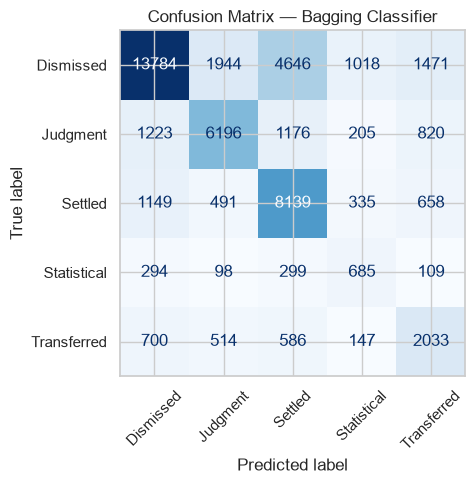

(0.6329433497536946,
 0.6721041886259239,
 0.6329433497536946,
 0.6409191385205893,
 0.8546225101076583)

In [18]:
t0 = time.time()
bag_clf = BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=15, class_weight="balanced", random_state=RANDOM_STATE),
    n_estimators=50, max_samples=0.8, random_state=RANDOM_STATE, n_jobs=-1,
)
bag_clf.fit(X_train_final, y_clf_train)
fit_seconds = time.time() - t0

pred_bag = bag_clf.predict(X_test_final)
proba_bag = bag_clf.predict_proba(X_test_final)

fitted_models_clf["Bagging Classifier"] = bag_clf
test_preds_clf["Bagging Classifier"] = pred_bag
test_probas_clf["Bagging Classifier"] = proba_bag

evaluate_classifier("Bagging Classifier", y_clf_test, pred_bag, proba_bag, fit_seconds,
                     classes=bag_clf.classes_.tolist())

Feature importance (averaged across base estimators) — Bagging Classifier

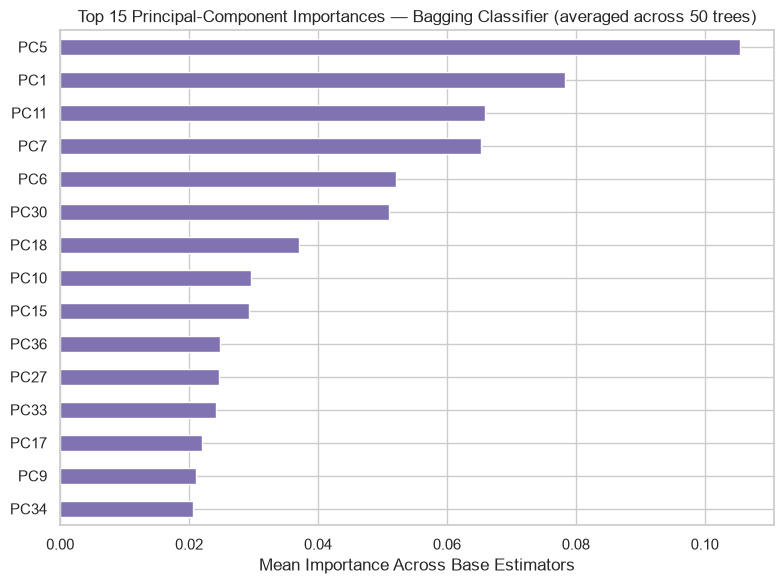

In [19]:
import numpy as np
bag_importances_matrix = np.array([est.feature_importances_ for est in bag_clf.estimators_])
bag_importances = pd.Series(bag_importances_matrix.mean(axis=0), index=X_train_final.columns)
top_bag = bag_importances.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 6))
top_bag.sort_values().plot(kind="barh", ax=ax, color="#8172B2")
ax.set_title("Top 15 Principal-Component Importances — Bagging Classifier (averaged across 50 trees)")
ax.set_xlabel("Mean Importance Across Base Estimators")
plt.tight_layout()
plt.show()

#### 10. MLP Classifier (Neural Network)


===== MLP Classifier =====
Accuracy=0.6633  Precision(weighted)=0.6639  Recall(weighted)=0.6633  F1(weighted)=0.6514  ROC-AUC(OvR, weighted)=0.8544  (fit time 111.3s)
              precision    recall  f1-score   support

   Dismissed       0.69      0.79      0.74     22863
    Judgment       0.70      0.59      0.64      9620
     Settled       0.59      0.65      0.62     10772
 Statistical       0.78      0.19      0.31      1485
 Transferred       0.59      0.30      0.40      3980

    accuracy                           0.66     48720
   macro avg       0.67      0.51      0.54     48720
weighted avg       0.66      0.66      0.65     48720



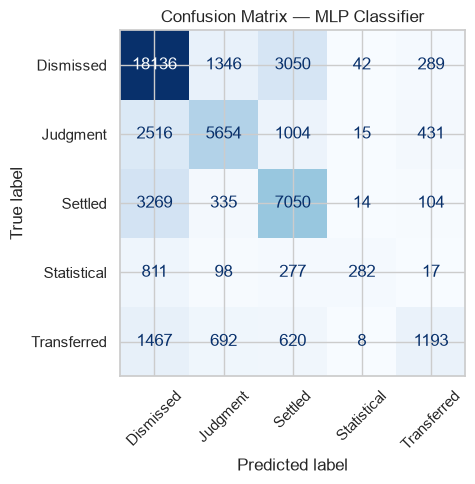

Converged after 47 iterations.


In [20]:
t0 = time.time()
mlp_clf = MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", max_iter=300,
                         early_stopping=True, random_state=RANDOM_STATE)
mlp_clf.fit(X_train_final, y_clf_train)
fit_seconds = time.time() - t0

pred_mlp = mlp_clf.predict(X_test_final)
proba_mlp = mlp_clf.predict_proba(X_test_final)

fitted_models_clf["MLP Classifier"] = mlp_clf
test_preds_clf["MLP Classifier"] = pred_mlp
test_probas_clf["MLP Classifier"] = proba_mlp

evaluate_classifier("MLP Classifier", y_clf_test, pred_mlp, proba_mlp, fit_seconds,
                     classes=mlp_clf.classes_.tolist())
print(f"Converged after {mlp_clf.n_iter_} iterations.")

Training loss curve — MLP Classifier

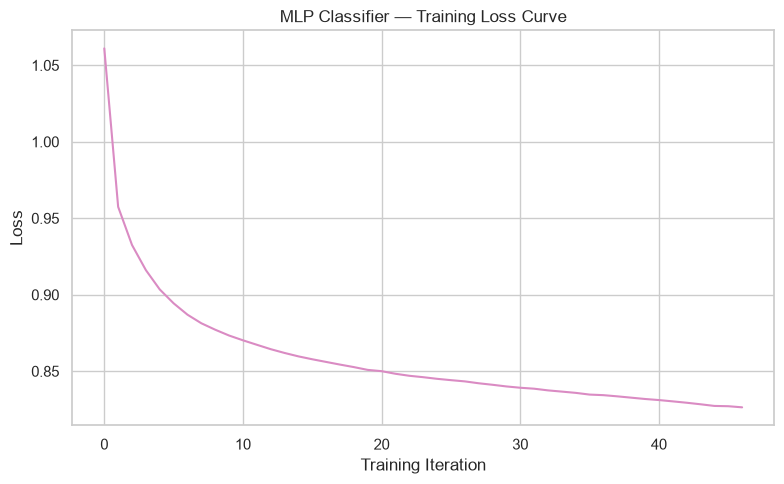

In [21]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(mlp_clf.loss_curve_, color="#DA8BC3")
ax.set_title("MLP Classifier — Training Loss Curve")
ax.set_xlabel("Training Iteration")
ax.set_ylabel("Loss")
plt.tight_layout()
plt.show()

#### 11. Single-Layer Perceptron
The 37 PCA inputs connect straight to the 5 outcome neurons, with no hidden layer, so it can only learn linear (straight-line) boundaries. It is the baseline that shows what the MLP's hidden layers add.


===== Single-Layer Perceptron =====
Accuracy=0.4450  Precision(weighted)=0.4284  Recall(weighted)=0.4450  F1(weighted)=0.4234  ROC-AUC(OvR, weighted)=0.6267  (fit time 2.3s)
              precision    recall  f1-score   support

   Dismissed       0.55      0.67      0.60     22863
    Judgment       0.28      0.36      0.31      9620
     Settled       0.46      0.23      0.30     10772
 Statistical       0.07      0.01      0.02      1485
 Transferred       0.17      0.12      0.14      3980

    accuracy                           0.45     48720
   macro avg       0.30      0.28      0.27     48720
weighted avg       0.43      0.45      0.42     48720



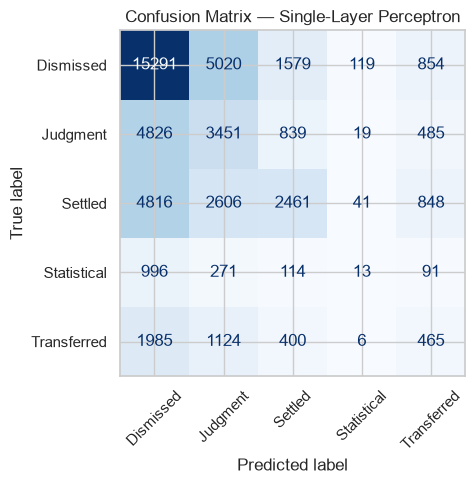

Stopped after 14 epochs.


In [22]:
from sklearn.linear_model import Perceptron

t0 = time.time()
slp_clf = Perceptron(max_iter=1000, tol=1e-3, early_stopping=True, random_state=RANDOM_STATE, n_jobs=-1)
slp_clf.fit(X_train_final, y_clf_train)
fit_seconds = time.time() - t0

pred_slp = slp_clf.predict(X_test_final)
scores_slp = slp_clf.decision_function(X_test_final)
proba_slp = np.exp(scores_slp - scores_slp.max(axis=1, keepdims=True))
proba_slp = proba_slp / proba_slp.sum(axis=1, keepdims=True)  # softmax of the scores, used for ROC-AUC

fitted_models_clf["Single-Layer Perceptron"] = slp_clf
test_preds_clf["Single-Layer Perceptron"] = pred_slp
test_probas_clf["Single-Layer Perceptron"] = proba_slp

evaluate_classifier("Single-Layer Perceptron", y_clf_test, pred_slp, proba_slp, fit_seconds,
                     classes=slp_clf.classes_.tolist())
print(f"Stopped after {slp_clf.n_iter_} epochs.")


Network diagrams: single-layer perceptron vs MLP

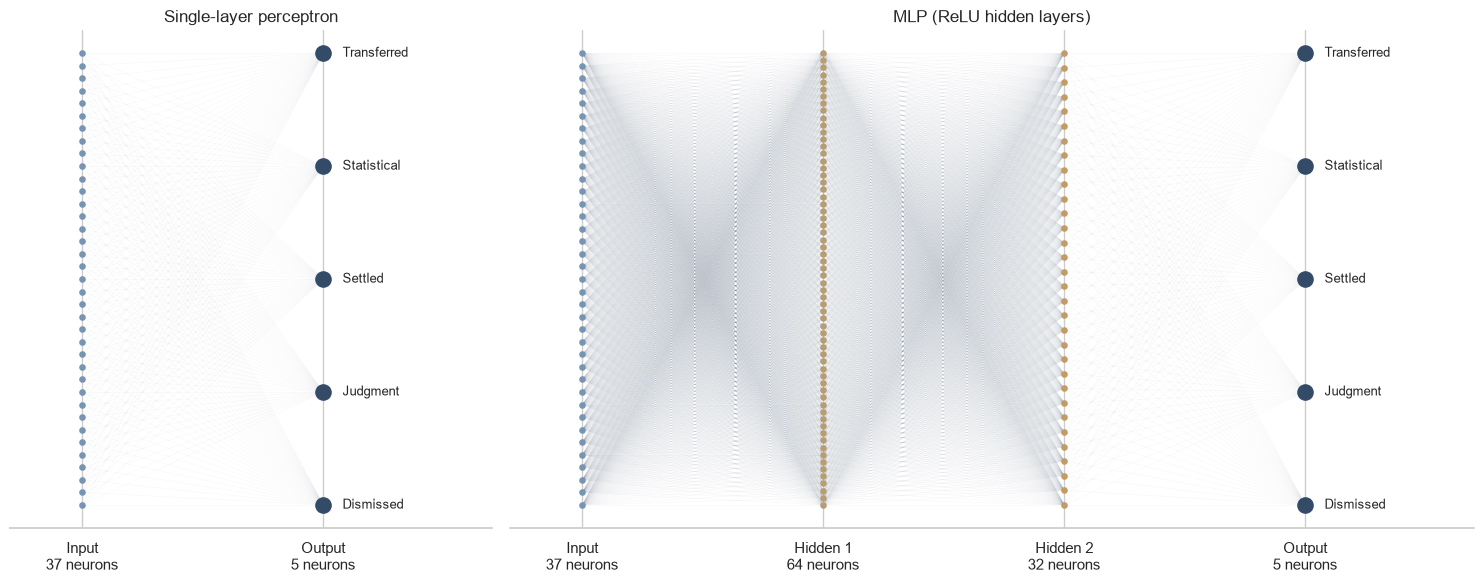

In [23]:
def draw_network(ax, sizes, title, classes):
    """Every neuron as a dot and every weight as a line, layer by layer."""
    names = ["Input"] + [f"Hidden {i}" for i in range(1, len(sizes) - 1)] + ["Output"]
    pos = [[(l, i / (n - 1) if n > 1 else 0.5) for i in range(n)] for l, n in enumerate(sizes)]
    for l in range(len(sizes) - 1):
        for a in pos[l]:
            for b in pos[l + 1]:
                ax.plot([a[0], b[0]], [a[1], b[1]], color="#344B68", alpha=0.04, linewidth=0.4)
    colours = ["#7794B2", "#B69D74", "#C49B63", "#344B68"]
    for l, layer in enumerate(pos):
        last = l == len(sizes) - 1
        ax.scatter([p[0] for p in layer], [p[1] for p in layer], s=120 if last else 14, zorder=3,
                   color=colours[-1] if last else colours[min(l, 2)])
        if last:
            for (x, y), c in zip(layer, classes):
                ax.text(x + 0.08, y, c, va="center", fontsize=9)
    ax.set_xticks(range(len(sizes)), [f"{n}\n{s} neurons" for n, s in zip(names, sizes)])
    ax.set_yticks([])
    ax.set_xlim(-0.3, len(sizes) - 0.3)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.set_title(title)

n_inputs = X_train_final.shape[1]
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 2]})
draw_network(axes[0], [n_inputs, len(CLASS_LABELS)], "Single-layer perceptron", CLASS_LABELS)
draw_network(axes[1], [n_inputs, *mlp_clf.hidden_layer_sizes, len(CLASS_LABELS)], "MLP (ReLU hidden layers)", CLASS_LABELS)
plt.tight_layout()
plt.show()


---
### Consolidated comparison table (Part A + Part B + single-layer perceptron)

In [24]:
comparison_clf_df_full = pd.DataFrame(results_clf).drop_duplicates(subset="Model", keep="last")
comparison_clf_df_full = comparison_clf_df_full.sort_values("F1", ascending=False).reset_index(drop=True)
comparison_clf_df_full.index = comparison_clf_df_full.index + 1
comparison_clf_df_full.insert(0, "Rank", comparison_clf_df_full.index)

print(f"Total algorithms compared: {len(comparison_clf_df_full)}")
comparison_clf_df_full[["Rank", "Model", "Accuracy", "Precision", "Recall", "F1", "ROC_AUC_OvR", "Fit_Seconds"]].round(4)

Total algorithms compared: 11


,Rank,Model,Accuracy,Precision,Recall,F1,ROC_AUC_OvR,Fit_Seconds
1,1,MLP Classifier,0.6633,0.6639,0.6633,0.6514,0.8544,111.3340
2,2,Bagging Classifier,0.6329,0.6721,0.6329,0.6409,0.8546,168.7640
3,3,Random Forest Classifier,0.6164,0.6735,0.6164,0.6263,0.8577,23.6929
4,4,Gradient Boosting Classifier,0.6255,0.6365,0.6255,0.6051,0.8262,1888.2846
5,5,Decision Tree Classifier,0.5445,0.6202,0.5445,0.5624,0.8021,68.7201
6,6,KNN Classifier,0.5711,0.5599,0.5711,0.5580,0.7630,0.2839
7,7,SVC,0.5240,0.6067,0.5240,0.5370,0.7995,194.8054
8,8,Naive Bayes (Gaussian),0.5017,0.5067,0.5017,0.4997,0.7189,2.6170
9,9,AdaBoost Classifier,0.5449,0.5113,0.5449,0.4980,0.7462,167.9221
10,10,Logistic Regression,0.4425,0.5654,0.4425,0.4637,0.7576,11.3237


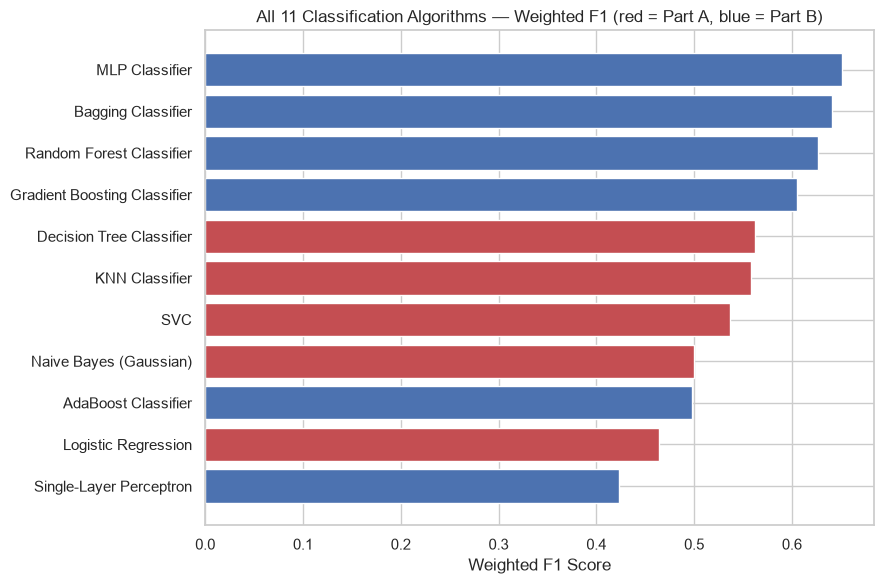

In [25]:
fig, ax = plt.subplots(figsize=(9, 6))
plot_df = comparison_clf_df_full.sort_values("F1")
part_a_models = ["Logistic Regression", "KNN Classifier", "Naive Bayes (Gaussian)",
                  "Decision Tree Classifier", "SVC"]
colors = ["#C44E52" if m in part_a_models else "#4C72B0" for m in plot_df["Model"]]
ax.barh(plot_df["Model"], plot_df["F1"], color=colors)
ax.set_xlabel("Weighted F1 Score")
ax.set_title(f"All {len(plot_df)} Classification Algorithms — Weighted F1 (red = Part A, blue = Part B)")
plt.tight_layout()
plt.show()

---
### Final model selection & hyperparameter tuning

In [26]:
best_model_name = comparison_clf_df_full.iloc[0]["Model"]
f1_before = comparison_clf_df_full.loc[comparison_clf_df_full["Model"] == best_model_name, "F1"].values[0]
print(f"Best model by weighted F1: {best_model_name}")
print(f"F1 before tuning: {f1_before:.4f}")

Best model by weighted F1: MLP Classifier
F1 before tuning: 0.6514


In [27]:
import time
import pandas as pd

from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score


tuning_grids = {

    "Bagging Classifier": (
        BaggingClassifier(
            estimator=DecisionTreeClassifier(
                class_weight="balanced",
                random_state=RANDOM_STATE
            ),
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        {
            "n_estimators": [30, 50, 80],
            "max_samples": [0.6, 0.8, 1.0],
            "estimator__max_depth": [10, 15, None]
        }
    ),

    "MLP Classifier": (
        MLPClassifier(
            random_state=RANDOM_STATE,
            early_stopping=True
        ),
        {
            "hidden_layer_sizes": [
                (32,),
                (64,),
                (64, 32),
                (128, 64)
            ],
            "activation": [
                "relu",
                "tanh"
            ],
            "learning_rate_init": [
                0.0005,
                0.001,
                0.005
            ],
            "alpha": [
                0.0001,
                0.001,
                0.01
            ],
            "batch_size": [
                64,
                128,
                "auto"
            ],
            "max_iter": [
                300,
                500
            ]
        }
    )
}


TUNE_SAMPLE_SIZE = 60000

if len(X_train_final) > TUNE_SAMPLE_SIZE:

    X_train_tune, _, y_train_tune, _ = train_test_split(
        X_train_final,
        y_clf_train,
        train_size=TUNE_SAMPLE_SIZE,
        stratify=y_clf_train,
        random_state=RANDOM_STATE
    )

else:

    X_train_tune = X_train_final
    y_train_tune = y_clf_train


tuning_results = []
tuned_models = {}


for model_name, (estimator, param_grid) in tuning_grids.items():

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    original_model = fitted_models_clf[model_name]

    pred_before = original_model.predict(X_test_final)

    accuracy_before = accuracy_score(
        y_clf_test,
        pred_before
    )

    f1_before = f1_score(
        y_clf_test,
        pred_before,
        average="weighted",
        zero_division=0
    )

    t0 = time.time()

    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=param_grid,
        n_iter=5,
        cv=3,
        scoring="accuracy",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=1
    )

    search.fit(
        X_train_tune,
        y_train_tune
    )

    tuning_time = time.time() - t0

    best_model = search.best_estimator_

    best_model.fit(
        X_train_final,
        y_clf_train
    )

    pred_after = best_model.predict(
        X_test_final
    )

    accuracy_after = accuracy_score(
        y_clf_test,
        pred_after
    )

    f1_after = f1_score(
        y_clf_test,
        pred_after,
        average="weighted",
        zero_division=0
    )

    accuracy_improvement = (
        accuracy_after - accuracy_before
    )

    f1_improvement = (
        f1_after - f1_before
    )

    print("Best Parameters:")
    print(search.best_params_)

    print(f"Accuracy Before : {accuracy_before:.4f}")
    print(f"Accuracy After  : {accuracy_after:.4f}")
    print(f"Accuracy Change : {accuracy_improvement:+.4f}")

    print(f"F1 Before       : {f1_before:.4f}")
    print(f"F1 After        : {f1_after:.4f}")
    print(f"F1 Change       : {f1_improvement:+.4f}")

    print(f"Best CV Accuracy: {search.best_score_:.4f}")
    print(f"Tuning Time     : {tuning_time:.2f} seconds")

    tuning_results.append({
        "Model": model_name,
        "Accuracy Before": accuracy_before,
        "Accuracy After": accuracy_after,
        "Accuracy Improvement": accuracy_improvement,
        "F1 Before": f1_before,
        "F1 After": f1_after,
        "F1 Improvement": f1_improvement,
        "Best CV Accuracy": search.best_score_,
        "Best Parameters": search.best_params_,
        "Tuning Time": tuning_time
    })

    tuned_models[model_name] = best_model


comparison_tuning = pd.DataFrame(
    tuning_results
)

print("\n")
print("=" * 80)
print("BAGGING + MLP TUNING RESULTS")
print("=" * 80)

print(
    comparison_tuning[
        [
            "Model",
            "Accuracy Before",
            "Accuracy After",
            "Accuracy Improvement",
            "F1 Before",
            "F1 After",
            "F1 Improvement"
        ]
    ].round(4).to_string(index=False)
)


for model_name, model in tuned_models.items():

    tuned_key = f"{model_name} (Tuned)"

    fitted_models_clf[tuned_key] = model

    test_preds_clf[tuned_key] = model.predict(
        X_test_final
    )

    test_probas_clf[tuned_key] = model.predict_proba(
        X_test_final
    )


Bagging Classifier
Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best Parameters:
{'n_estimators': 30, 'max_samples': 0.6, 'estimator__max_depth': 15}
Accuracy Before : 0.6329
Accuracy After  : 0.6318
Accuracy Change : -0.0012
F1 Before       : 0.6409
F1 After        : 0.6392
F1 Change       : -0.0017
Best CV Accuracy: 0.6266
Tuning Time     : 211.00 seconds

MLP Classifier
Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best Parameters:
{'max_iter': 300, 'learning_rate_init': 0.005, 'hidden_layer_sizes': (64, 32), 'batch_size': 'auto', 'alpha': 0.01, 'activation': 'tanh'}
Accuracy Before : 0.6633
Accuracy After  : 0.6654
Accuracy Change : +0.0021
F1 Before       : 0.6514
F1 After        : 0.6523
F1 Change       : +0.0010
Best CV Accuracy: 0.6479
Tuning Time     : 48.23 seconds


BAGGING + MLP TUNING RESULTS
             Model  Accuracy Before  Accuracy After  Accuracy Improvement  F1 Before  F1 After  F1 Improvement
Bagging Classifier           0.6329       

---
### Save final results

In [29]:
import os
os.makedirs('../data/processed', exist_ok=True)
os.makedirs('../models', exist_ok=True)

# The tuning cell above tunes Bagging and MLP and fills `tuning_results`.
# Keep the tuned model with the best test F1, and use it only if it beats the best untuned model.
best_tuning = max(tuning_results, key=lambda r: r["F1 After"])
tuned_key = f"{best_tuning['Model']} (Tuned)"
best_untuned_f1 = comparison_clf_df_full.iloc[0]["F1"]
final_clf_key = tuned_key if best_tuning["F1 After"] > best_untuned_f1 else best_model_name

tuning_result = {
    'model_name':     best_tuning['Model'],
    'tuned_key':      tuned_key,
    'best_params':    best_tuning['Best Parameters'],
    'before':         {'accuracy': round(best_tuning['Accuracy Before'], 4), 'f1': round(best_tuning['F1 Before'], 4)},
    'after':          {'accuracy': round(best_tuning['Accuracy After'], 4), 'f1': round(best_tuning['F1 After'], 4)},
    'improvement_f1': round(best_tuning['F1 Improvement'], 4),
    'all_models':     tuning_results,   # Bagging and MLP, before/after
}

joblib.dump({
    'comparison_clf_df_full': comparison_clf_df_full,
    'best_model_name':        best_model_name,
    'fitted_models_clf':      fitted_models_clf,   # includes the "(Tuned)" variants
    'CLASS_LABELS':           CLASS_LABELS,
    'tuning_result':          tuning_result,
}, '../data/processed/classification_final_results.pkl')

joblib.dump(fitted_models_clf[final_clf_key], '../models/best_classifier.pkl')

print(f"Saved results. Best classifier: '{final_clf_key}'")
print(f"Best tuned model: {tuned_key}  F1 {tuning_result['before']['f1']:.4f} -> {tuning_result['after']['f1']:.4f} "
      f"({tuning_result['improvement_f1']:+.4f})")

Saved results. Best classifier: 'MLP Classifier (Tuned)'
Best tuned model: MLP Classifier (Tuned)  F1 0.6514 -> 0.6523 (+0.0010)
